# Tarif bandara, waktu terisi, dan waktu operasi yang belum terukur

**Pertanyaan bisnis:** apakah operator taksi perlu memprioritaskan perjalanan dari JFK atau LaGuardia menuju Manhattan dibandingkan perjalanan di dalam Manhattan?

**Sumber:** NYC TLC Yellow Taxi, Januari-April 2025. Januari-Maret membentuk perbandingan awal; April menjadi pembanding waktu berikutnya. Lingkup utama memakai pembayaran kartu/tunai dan kode tarif 1/2. Lihat `docs/METODOLOGI_ID.md` untuk seluruh aturan.

**Metrik utama:** jumlah `fare_amount` dibagi jumlah jam terisi. Waktu antre, perjalanan kosong, dan biaya operasi belum tersedia untuk menghitung pendapatan bersih atau hasil satu shift penuh.

**Data mentah lengkap:** `data/raw/` berisi 17 bagian CSV perjalanan dan referensi zona. Panduan membuka: `docs/PANDUAN_DATA_MENTAH_ID.md`. Notebook ini menggunakan agregat tersimpan agar ringan; transformasi seluruh data ada pada SQL dan `scripts/analyze.py`.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'outputs').exists() else Path.cwd().parent
metrics = json.loads((ROOT / 'outputs/metrics.json').read_text(encoding='utf-8'))
groups = pd.read_csv(ROOT / 'outputs/groups.csv')
display(pd.DataFrame([metrics['kpis']]))

,source_trips,eligible_trips,study_trips,study_fare_usd,study_occupied_hours
0,15168579,11044733,10148555,1.553224e+08,2.275190e+06


## 1. Tentukan populasi sebelum membandingkan rute

Sumber tidak memiliki ID perjalanan publik yang dijamin unik. Baris dipertahankan; tanda tangan nilai berulang tidak otomatis dihapus. Kunci referensi zona harus unik agar join tidak menggandakan baris. Waterfall menggunakan aturan pertama yang gagal agar jumlahnya kembali ke total sumber.

Perjalanan dengan pickup atau drop-off pada 9 Maret dikeluarkan karena perubahan daylight-saving time. Lihat pengecualian beserta jumlahnya di bawah. `eligible` adalah baris yang memenuhi aturan; rute penelitian merupakan bagian dari seluruh baris layak.


In [2]:
display(pd.DataFrame(metrics['quality']['waterfall']))
assert metrics['quality']['all_checks_passed']
assert sum(x['trips'] for x in metrics['quality']['waterfall']) == metrics['kpis']['source_trips']
display(pd.DataFrame(metrics['quality']['checks'].items(), columns=['check','passed']))

,cohort_status,trips
0,02_outside_source_month,93
1,03_outside_card_cash,3448522
2,04_outside_ratecodes_1_2,333102
3,05_dst_transition_day,82063
4,06_nonpositive_duration,60707
5,07_nonpositive_distance,63174
6,08_distance_over_100mi,29
7,09_nonpositive_fare,56763
8,10_fare_over_500usd,4
9,11_duration_under_1min,16512


,check,passed
0,source_row_count_matches_manifest,True
1,zone_lookup_unique,True
2,waterfall_reconciles,True
3,three_study_routes,True
4,positive_study_duration,True
5,no_dst_transition_records,True
6,group_trips_reconcile,True
7,daily_trips_reconcile,True
8,broad_contains_primary,True


## 2. Hindari perangkap rata-rata rasio

Contoh: tarif USD 20 membutuhkan 10 menit, lalu tarif USD 20 lain membutuhkan 50 menit. Rata-rata tarif per jam kedua perjalanan adalah USD 72/jam. Namun, total USD 40 selama 60 menit menghasilkan USD 40/jam. Karena itu, tarif dan menit dijumlahkan dahulu, baru dibagi.

Tabel berikut menampilkan periode, rute, jumlah perjalanan, rata-rata tarif, rata-rata durasi, tarif per jam terisi, serta batas interval. Nama kolom teknis dipertahankan agar dapat dicocokkan dengan CSV hasil dan SQL. Grafik sumber memakai label bahasa Inggris: `train` = Januari-Maret, `holdout` = April.


,period,route,trips,mean_fare_usd,mean_minutes,fare_per_occupied_hour,ci_low,ci_high
0,holdout,JFK → Manhattan,75303,70.17,53.56,78.60,76.14,81.38
1,holdout,LaGuardia → Manhattan,71029,43.41,31.24,83.39,80.84,86.17
2,holdout,Manhattan → Manhattan,2531836,13.42,12.53,64.31,63.61,65.13
3,train,JFK → Manhattan,197073,70.14,48.45,86.86,84.78,88.99
4,train,LaGuardia → Manhattan,186178,42.41,28.47,89.36,87.81,90.94
5,train,Manhattan → Manhattan,7087136,12.88,11.81,65.41,65.02,65.84


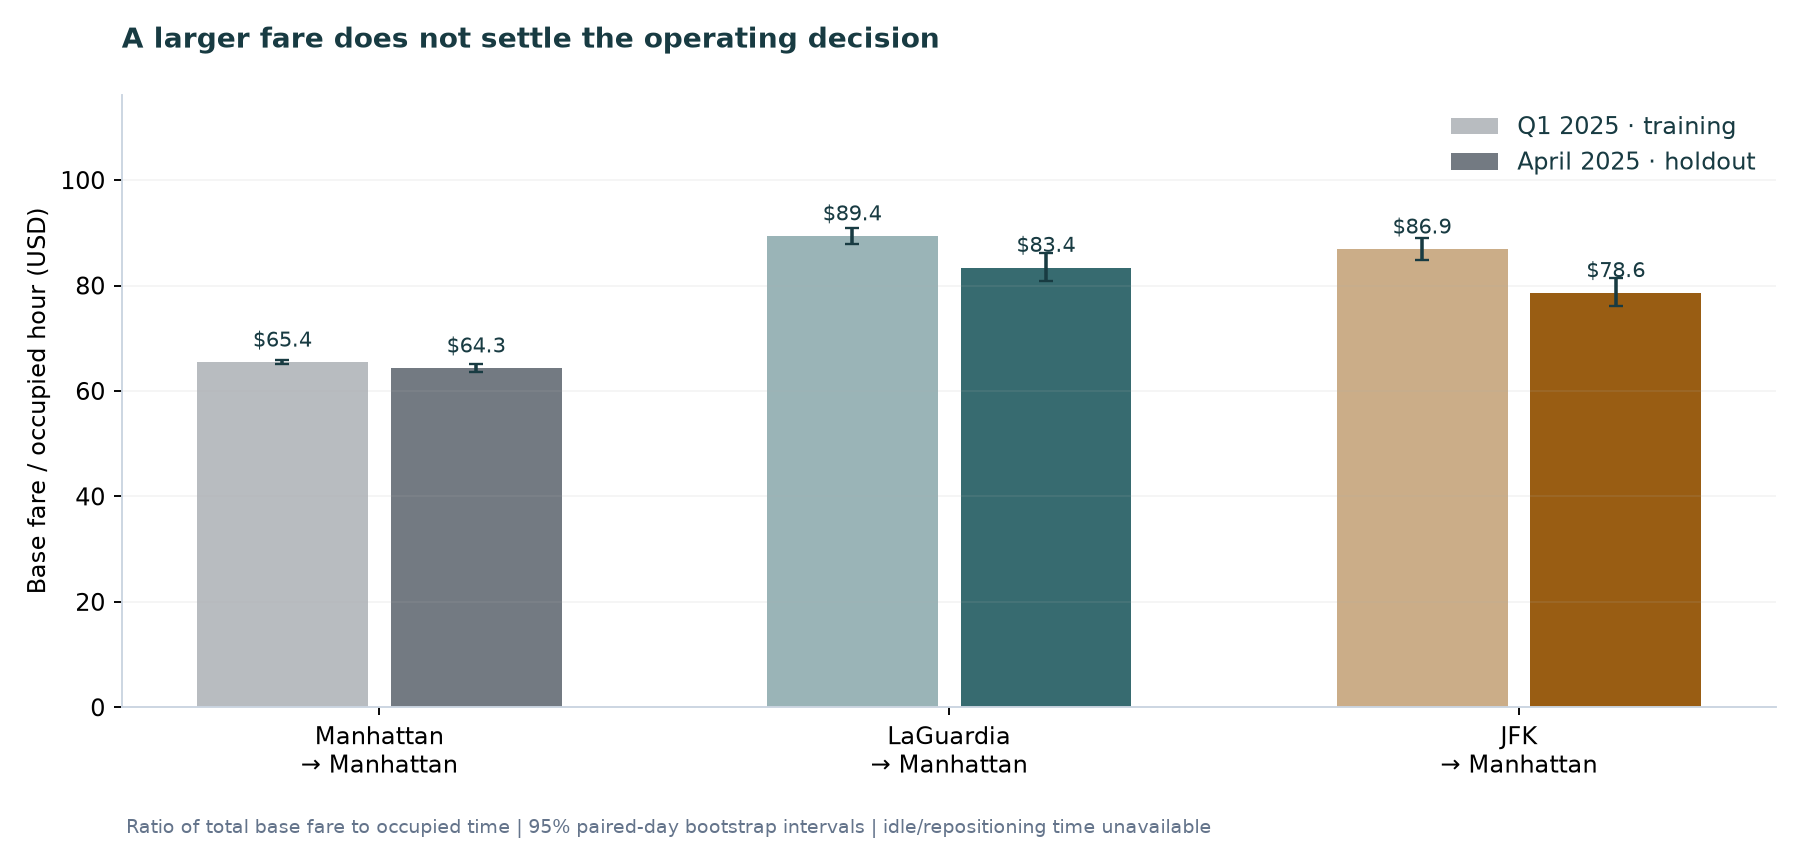

In [3]:
display(groups[['period','route','trips','mean_fare_usd','mean_minutes','fare_per_occupied_hour','ci_low','ci_high']].round(2))
display(Image(filename=str(ROOT / 'outputs/charts/01_route_holdout.png')))

## 3. Periksa April sebagai pembanding berikutnya

Definisi rute dan aturan dibekukan sebelum membandingkan April. Interval ketidakpastian berasal dari 2.000 bootstrap harian berpasangan: seluruh rute memakai pilihan hari yang sama untuk mempertahankan kondisi harian bersama.

Interval menggambarkan variasi hari dalam periode yang tersedia. Ia tidak menghilangkan perbedaan pemilihan rute atau mengukur dampak kausal perubahan penempatan taksi. Grafik jam pickup juga hanya menggambarkan perjalanan yang teramati, tanpa mengukur permintaan yang tidak terlayani.


,route,train_rate,holdout_rate,change_pct,train_rank,holdout_rank
0,Manhattan → Manhattan,65.41,64.31,-1.69,3,3
1,LaGuardia → Manhattan,89.36,83.39,-6.69,1,1
2,JFK → Manhattan,86.86,78.60,-9.51,2,2


,period,route,ratio_to_city,ratio_ci_low,ratio_ci_high
0,train,LaGuardia → Manhattan,1.366,1.348,1.385
1,train,JFK → Manhattan,1.328,1.300,1.355
2,holdout,LaGuardia → Manhattan,1.297,1.267,1.327
3,holdout,JFK → Manhattan,1.222,1.194,1.252


Urutan rute bertahan pada April: True


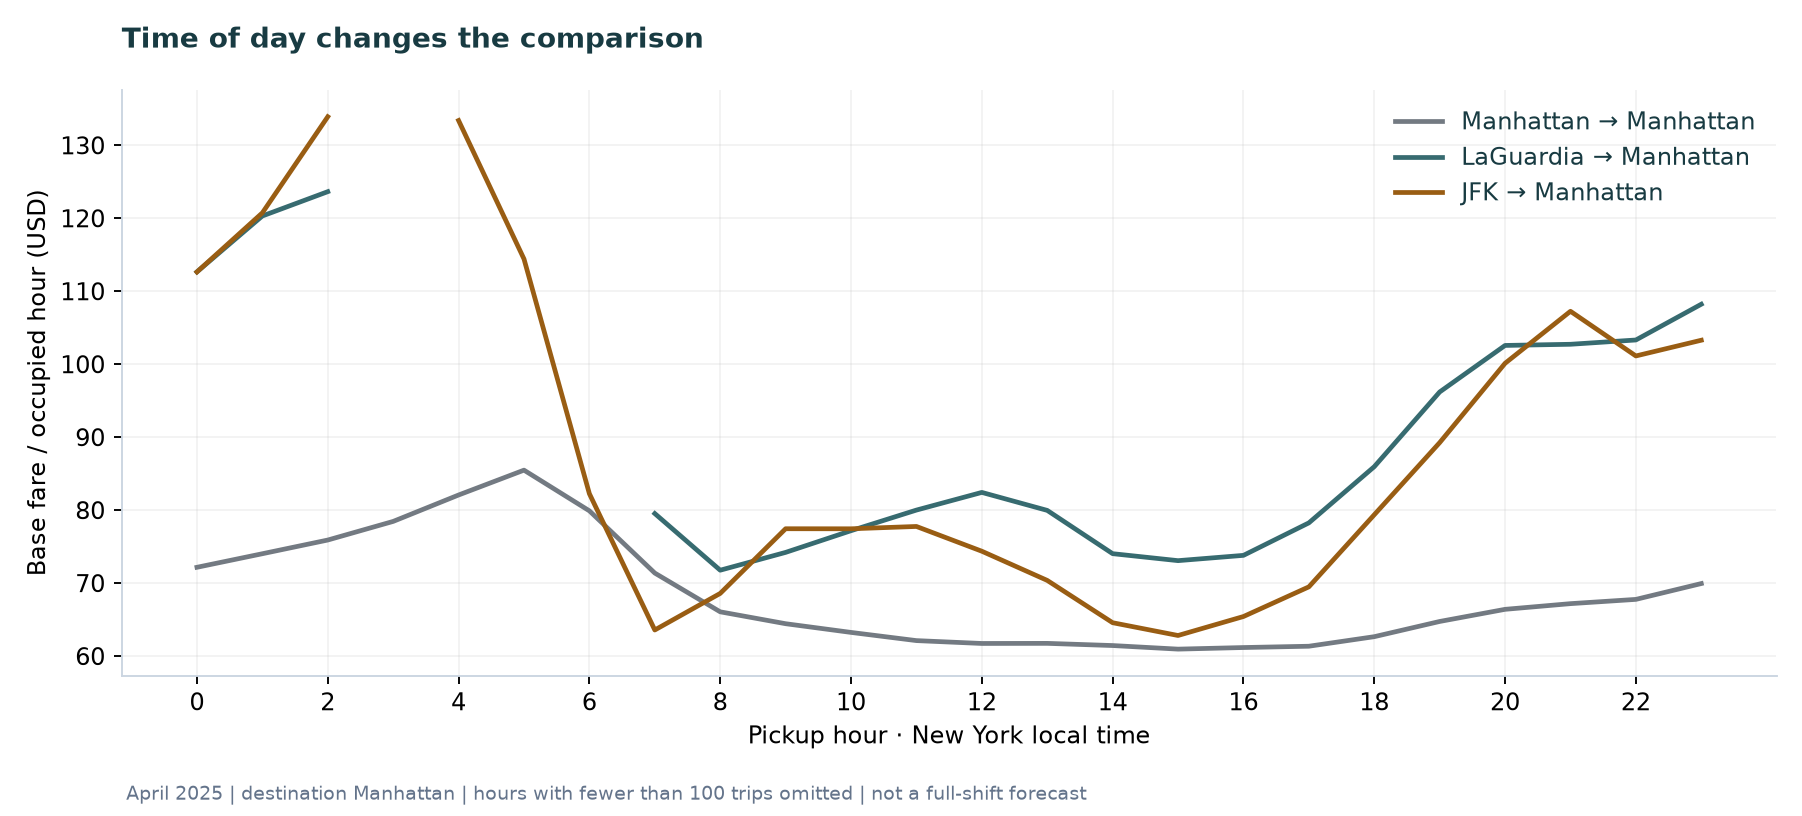

In [4]:
display(pd.DataFrame(metrics['holdout']['groups']).round(2))
display(pd.DataFrame(metrics['bootstrap']['comparisons']).round(3))
print('Urutan rute bertahan pada April:', metrics['holdout']['ranking_preserved'])
display(Image(filename=str(ROOT / 'outputs/charts/02_hourly_holdout.png')))

## 4. Uji sensitivitas batas filter

Pemeriksaan lebih longgar memakai durasi positif sampai 240 menit dan tarif dasar positif sampai USD 1.000. Aturan lainnya tetap sama. Ini menguji dua batas tersebut, bukan seluruh kemungkinan keputusan pembersihan.

Bandingkan `fare_per_occupied_hour` dengan `primary_rate`, lalu periksa `rank` dan `primary_rank`. Persentase perubahan tercatat di `rate_change_pct`.


In [5]:
display(pd.DataFrame(metrics['sensitivity']['groups'])[['period','route','trips','fare_per_occupied_hour','primary_rate','rate_change_pct','rank','primary_rank']].round(2))
print('Urutan rute bertahan pada filter lebih longgar:', metrics['sensitivity']['ranking_preserved'])

,period,route,trips,fare_per_occupied_hour,primary_rate,rate_change_pct,rank,primary_rank
0,holdout,JFK → Manhattan,75319,78.61,78.60,0.01,2,2
1,holdout,LaGuardia → Manhattan,71031,83.37,83.39,-0.02,1,1
2,holdout,Manhattan → Manhattan,2535211,64.39,64.31,0.13,3,3
3,train,JFK → Manhattan,197122,86.86,86.86,-0.00,2,2
4,train,LaGuardia → Manhattan,186182,89.36,89.36,-0.01,1,1
5,train,Manhattan → Manhattan,7096834,65.51,65.41,0.15,3,3


Urutan rute bertahan pada filter lebih longgar: True


## 5. Nyatakan waktu yang hilang sebagai asumsi

Skenario menambahkan menit yang tidak teramati per perjalanan, terpisah untuk bandara dan kota. Asumsi awal 30 menit bandara dan 10 menit kota adalah ilustrasi, bukan hasil pengukuran.

`tarif per jam siklus = 60 x jumlah tarif dasar / (menit terisi + perjalanan x menit tambahan)`

`menit tambahan impas bandara = rata-rata tarif bandara / tarif per jam skenario kota x 60 - rata-rata menit terisi bandara`

Ambang adalah waktu tambahan saat hasil bandara menyamai pembanding kota yang dipilih. Nilai negatif berarti bandara sudah tertinggal pada nol menit tambahan. Angka tersebut tidak memasukkan biaya operasi.


,period,route,assumed_extra_minutes,scenario_fare_per_hour
0,train,Manhattan → Manhattan,10,35.42
1,train,LaGuardia → Manhattan,30,43.52
2,train,JFK → Manhattan,30,53.64
3,holdout,Manhattan → Manhattan,10,35.76
4,holdout,LaGuardia → Manhattan,30,42.54
5,holdout,JFK → Manhattan,30,50.38


,period,route,city_extra_minutes,airport_extra_minutes
0,train,LaGuardia → Manhattan,0,10.43
1,train,LaGuardia → Manhattan,10,43.36
2,train,LaGuardia → Manhattan,20,76.30
3,train,JFK → Manhattan,0,15.88
4,train,JFK → Manhattan,10,70.36
5,train,JFK → Manhattan,20,124.84
6,holdout,LaGuardia → Manhattan,0,9.27
7,holdout,LaGuardia → Manhattan,10,41.61
8,holdout,LaGuardia → Manhattan,20,73.95
9,holdout,JFK → Manhattan,0,11.91


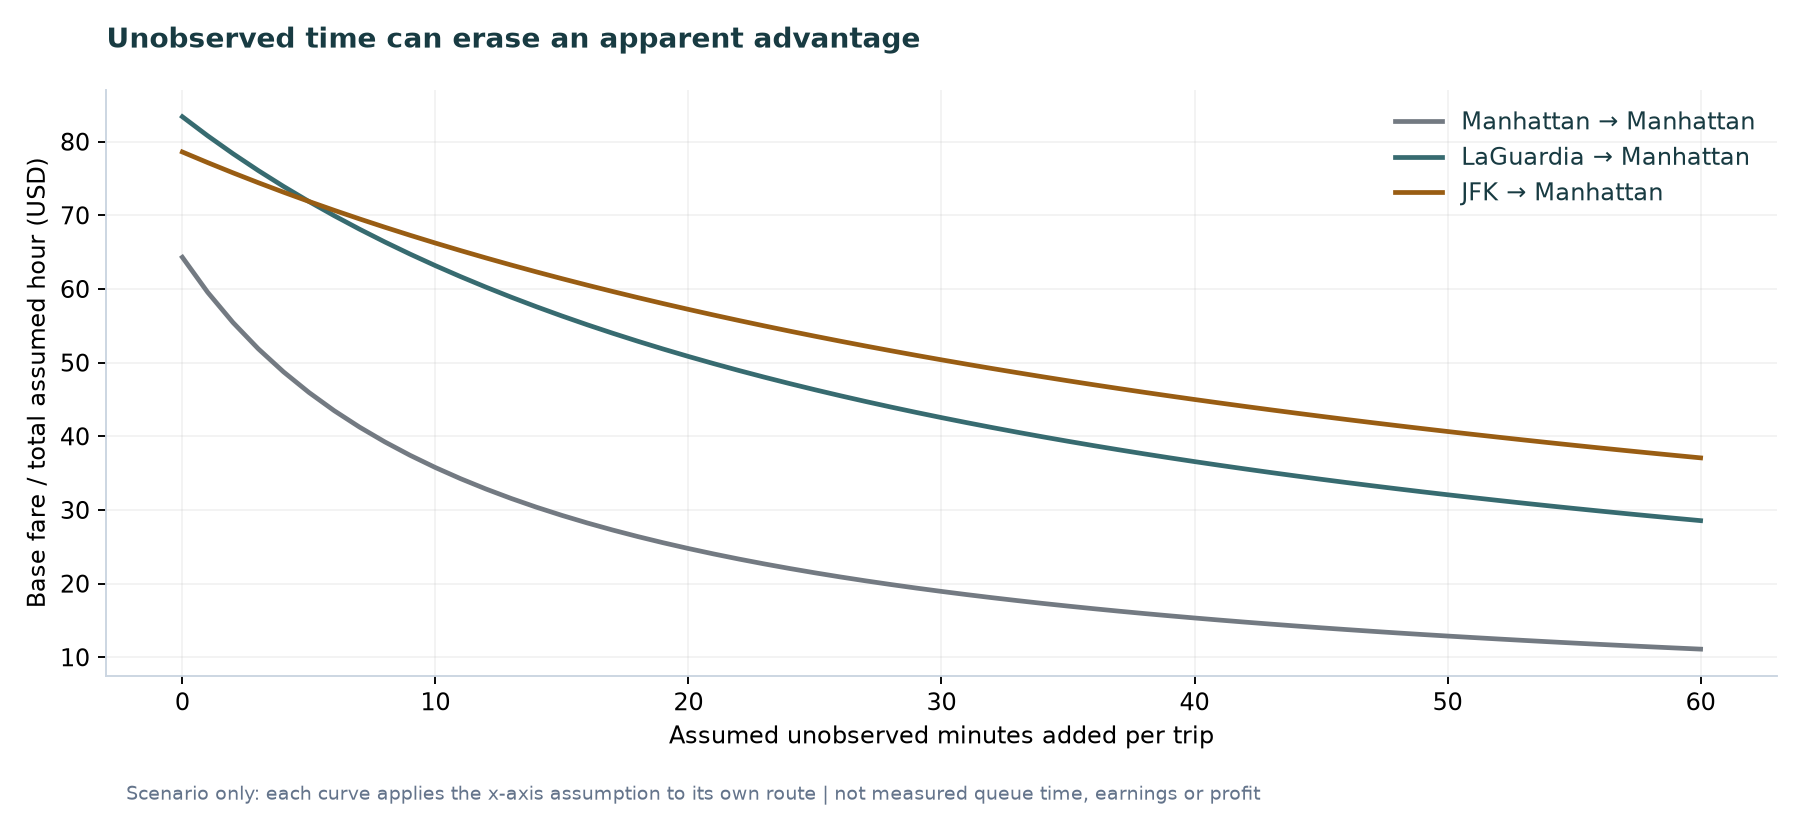

In [6]:
display(pd.DataFrame(metrics['scenarios']['default_rows']).round(2))
display(pd.DataFrame(metrics['scenarios']['break_even']).round(2))
display(Image(filename=str(ROOT / 'outputs/charts/03_extra_time_scenario.png')))

## 6. Pengukuran sebelum mengubah prioritas operasi

Ikuti `docs/EXPERIMENT_PLAN.md`: ukur waktu antre, idle, perjalanan kosong, perjalanan selesai per shift, pembayaran pengemudi, biaya operasi, dan kualitas layanan. Bandingkan kondisi operasi yang sesuai dan tetapkan keputusan sebelum melihat hasil.

Pilot yang diusulkan menggunakan pengacakan pada pengemudi, seluruh shift tetap mengikuti kelompok awal, dan analisis intention-to-treat. Data publik proyek ini belum menjalankan pilot tersebut.

**Jalankan ulang:** `python scripts/download_data.py`, `python scripts/export_raw_csv.py`, `python scripts/analyze.py`, `python -m unittest discover -s tests -v`, lalu `python scripts/build_notebook_id.py`.

Jejak sumber ada di `data/source_manifest.json`; jejak CSV lengkap ada di `data/raw_csv_manifest.json`. Setelah memahami analisis, pilih investigasi tambahan yang dapat Anda jelaskan sendiri, misalnya pemeriksaan Mei 2025.
